# 08 · หลักฐานสำหรับรายงานฉบับสมบูรณ์ — ทิศของความสัมพันธ์ · ปัญหาข้อมูล · ความแข็งแรง

**โครงงาน Sea Level × Wavelet Coherence · วิชา 01204496 · สัปดาห์ที่ 8 (W8)**

รายงานฉบับสมบูรณ์ (`reports/final/report.pdf`) เล่าผลแบบรายงานภูมิอากาศ: แผนที่ กลไก ใบรายงานผล สัญญาณไฟ
โน้ตบุ๊กนี้ตรวจ **ตัวเลขใหม่** ที่รายงานใช้แต่ยังไม่มีในโน้ตบุ๊ก 01–07 พร้อม assert

1. **เข็มทิศเฟส** — ทิศเฉลี่ยของความสัมพันธ์ที่อันดามันตรงกับที่กลไกคลื่นเคลวินทำนายไว้ *ก่อนดูผล* หรือไม่
   (ทิศที่คาดมาจากรายงานค้นคว้า `reports/กลไก ระดับน้ำทะเลไทย กับ ดัชนีภูมิอากาศ.md`)
2. **ระดับน้ำในหน่วยมิลลิเมตรเทียบเหตุการณ์** — ทำไมสหสัมพันธ์ทั้งอนุกรมต่ำ ทั้งที่ coherence มีนัยสำคัญ
3. **PSMSL − UHSLC** ของเกาะตะเภาน้อย — ขนาดของส่วนต่างแต่ละยุค
4. **สัญญาณไฟความแข็งแรง** — นับจากไฟล์ผลของการทดสอบความไวโดยตรง

รูปเรียกจาก `scripts/make_infographics.py` (ต้องรันด้วย `--group report` เพราะใช้ cartopy) — โน้ตบุ๊กแค่แสดงไฟล์รูป
แต่ **คำนวณตัวเลขที่ assert ใหม่เองทั้งหมด** ไม่ได้อ่านจากรูป

In [1]:
import json, sys
from pathlib import Path

import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))

import make_infographics as I
from wtc.plotting import use_thai_font

use_thai_font()
P = ROOT / "data" / "processed"
FIG = ROOT / "figures" / "report"
show = lambda name: display(Image(filename=str(FIG / f"{name}.png"))) if (FIG / f"{name}.png").exists() \
    else print(f"(ยังไม่มี {name}.png — รัน uv run --group report python scripts/make_infographics.py)")
q1 = np.load(P / "wtc_q1.npz", allow_pickle=True)
print("สถานี:", list(q1["stations"]), "· ดัชนี:", list(q1["indices"]))

สถานี: [np.str_('ko_taphao_noi'), np.str_('ko_lak'), np.str_('fort_phrachula_chomklao')] · ดัชนี: [np.str_('nino34'), np.str_('soi'), np.str_('pdo'), np.str_('amo'), np.str_('nao'), np.str_('tpi'), np.str_('dmi'), np.str_('wnpmi')]


## 1 · เข็มทิศเฟส: ทิศที่วัดได้ตรงกับที่กลไกทำนายไหม

กติกา (ตรวจด้วยอนุกรมสังเคราะห์ในรายงานค้นคว้า): `run_wtc.py` เรียก `wtc(Wy, Wx)` ⇒ θ = φ<sub>ระดับน้ำ</sub> − φ<sub>ดัชนี</sub>
* θ ≈ 0° ไปด้วยกัน · θ ≈ ±180° สวนทาง · θ > 0 (จากจุดอ้างอิง) ระดับน้ำนำ

กลไก: El Niño และ IOD บวก → ลมตะวันออกเหนือศูนย์สูตรมหาสมุทรอินเดีย → คลื่นเคลวินดูดน้ำขึ้น → **ระดับน้ำอันดามันต่ำลง**
⇒ คาด **สวนทาง** Niño3.4 และ DMI (≈180°) และ **ไปด้วยกัน** กับ SOI (≈0°, SOI เป็นลบช่วง El Niño)
WNPMI คาด 0°…+60° (มรสุม WNP อ่อนลง *หลัง* El Niño) — อันนี้เป็นการอนุมาน ไม่มีงานใดทดสอบ

เฉลี่ยมุมแบบวงกลม (เฉลี่ยเวกเตอร์หนึ่งหน่วย e^{iθ}) เฉพาะจุดที่ **มีนัยสำคัญ ∩ อยู่ใน COI ∩ ของเติม ≤ 50% ∩ คาบ 2–7 ปี**
ความยาวเวกเตอร์เฉลี่ย R บอกความสม่ำเสมอ (1 = ทุกจุดชี้ทางเดียวกัน)

In [2]:
st_, ix = [str(s) for s in q1["stations"]], [str(s) for s in q1["indices"]]
per = q1["periods"]; band = (per >= 2) & (per <= 7)
si = st_.index("ko_taphao_noi")

def in_sector(deg, lo, hi):
    # มุมอยู่ในช่วง [lo, hi] (องศา) โดยคิดแบบวงกลม
    return (deg - lo) % 360 <= (hi - lo) % 360

rows = {}
for k in ("soi", "nino34", "dmi", "wnpmi"):
    xi = ix.index(k)
    m = q1["sig"][si, xi] & q1["valid"][si, xi] & band[:, None]
    th = q1["phase"][si, xi][m].astype(float)
    z = np.exp(1j * th).mean()
    deg = np.degrees(np.angle(z))
    P_med = np.median((per[:, None] * np.ones(m.shape))[m])
    ref = 0 if abs(deg) < 90 else np.sign(deg) * 180
    lag = (deg - ref) / 360 * P_med * 12
    lo, hi, conf = I.EXPECTED[k]
    rows[k] = dict(n=int(m.sum()), theta=deg, R=abs(z), lag=lag, inside=in_sector(deg, lo, hi), conf=conf)
    print(f"{k:7s} n={m.sum():5d}  θ={deg:+7.1f}°  R={abs(z):.2f}  "
          f"{'ระดับน้ำนำ' if lag > 0 else 'ระดับน้ำตาม'} {abs(lag):4.1f} เดือน  "
          f"คาด [{lo}°, {hi}°] ({conf}) → {'✓' if rows[k]['inside'] else '✗'}")

assert all(r["inside"] for r in rows.values()), "มีดัชนีที่ทิศไม่ตรงกับที่กลไกคาด — ตรวจเครื่องหมายก่อนแปลผล"
assert rows["soi"]["R"] > 0.9 and rows["nino34"]["R"] > 0.9, "SOI/Niño3.4 ควรมีทิศสม่ำเสมอมาก"
# SOI กับ Niño3.4 วัดปรากฏการณ์เดียวกัน (กลับเครื่องหมาย) ⇒ ความหน่วงต้องใกล้กัน
assert abs(rows["soi"]["lag"] - rows["nino34"]["lag"]) < 1.5
# ตรงกับไฟล์ที่ make_infographics.py เขียนให้รายงาน
saved = json.loads((P / "phase_summary.json").read_text())
for k, r in rows.items():
    assert abs(saved[k]["theta"] - r["theta"]) < 1e-6
print("✅ ทิศตรงกลไกทั้ง 4 ดัชนี · ตรงกับ phase_summary.json ที่รายงานใช้")

soi     n= 2380  θ=  -28.0°  R=0.96  ระดับน้ำตาม  2.8 เดือน  คาด [-30°, 30°] (หนักแน่น) → ✓
nino34  n= 2135  θ= +156.3°  R=0.92  ระดับน้ำตาม  2.5 เดือน  คาด [150°, 210°] (หนักแน่น) → ✓
dmi     n= 2654  θ= -150.5°  R=0.55  ระดับน้ำนำ  4.7 เดือน  คาด [150°, 210°] (หนักแน่น) → ✓
wnpmi   n= 4990  θ=  +55.6°  R=0.97  ระดับน้ำนำ  5.5 เดือน  คาด [0°, 60°] (อนุมาน) → ✓
✅ ทิศตรงกลไกทั้ง 4 ดัชนี · ตรงกับ phase_summary.json ที่รายงานใช้


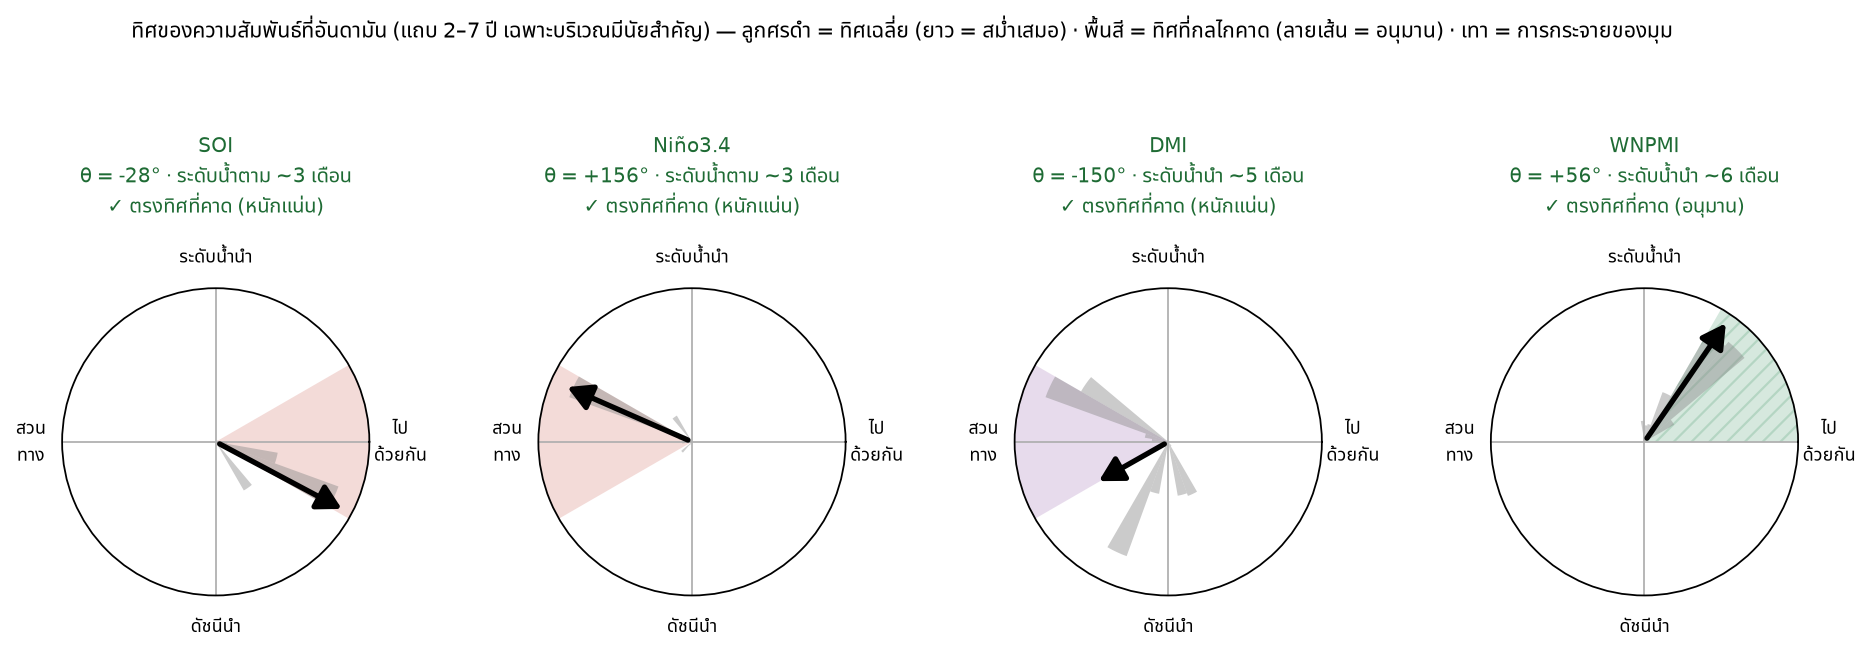

In [3]:
show("fig12_phase")

**อ่านผล** — SOI (−28°) กับ Niño3.4 (+156°) ให้ภาพเดียวกัน: ระดับน้ำ *ตาม* ENSO ราว 3 เดือน
DMI (−150°) สวนทางแต่ระดับน้ำลดลง *ก่อน* DMI ถึงจุดสูงสุดราว 5 เดือน ซึ่งเข้ากับที่อ่าวเบงกอลเริ่มต่ำตั้งแต่ เม.ย.
ขณะที่ IOD สูงสุด ก.ย.–พ.ย. (Aparna et al. 2012) แต่ R = 0.55 คือทิศกระจายกว่าตัวอื่น
WNPMI (+56°) ระดับน้ำ *นำ* ราว 6 เดือน ⇒ มรสุม WNP ตอบสนองทีหลัง น่าจะเป็น "ผลตาม" ของ ENSO มากกว่าตัวขับ
— เป็นอีกเหตุผลหนึ่ง (นอกจากปัญหาข้อมูลในหัวข้อ 3) ที่ไม่ควรสรุปว่า WNPMI เป็นดัชนีเด่น

## 2 · ความสัมพันธ์มาเป็นช่วง ๆ — ทำไมสหสัมพันธ์ทั้งอนุกรมต่ำ

แปลงระดับน้ำกลับเป็นมิลลิเมตรด้วยส่วนเบี่ยงเบนของ residual ที่ `build_series` จดไว้ แล้วเฉลี่ยเคลื่อนที่ 12 เดือน
**โดยไม่นับเดือนที่เป็นของเติม** (`I._running` ต้องมีเดือนจริง ≥ 9 จาก 12)

In [4]:
d = np.load(P / "series.npz", allow_pickle=True)
meta = json.loads(str(d["meta"]))
t, yn, xn = d["t"], [str(s) for s in d["y_names"]], [str(s) for s in d["x_names"]]
r_tab = {}
for st in ("ko_taphao_noi", "ko_lak"):
    i = yn.index(st)
    mm = np.where(d["Y_fill"][i], np.nan, d["Y"][i]) * meta["stats"][st]["resid_std"]
    sm = I._running(mm)
    for k in ("nino34", "dmi"):
        x = -I._running(d["X"][xn.index(k)])
        ok = np.isfinite(sm) & np.isfinite(x)
        r_tab[(st, k)] = np.corrcoef(sm[ok], x[ok])[0, 1]
    j97 = (t >= 1997.5) & (t < 1998.5)
    print(f"{st:14s} r(−Niño3.4)={r_tab[(st,'nino34')]:+.2f}  r(−DMI)={r_tab[(st,'dmi')]:+.2f}  "
          f"ต่ำสุดช่วง ก.ค.97–มิ.ย.98 = {np.nanmin(sm[j97]):+.0f} มม.")

ktn = yn.index("ko_taphao_noi")
sm_ktn = I._running(np.where(d["Y_fill"][ktn], np.nan, d["Y"][ktn]) * meta["stats"]["ko_taphao_noi"]["resid_std"])
assert np.nanmin(sm_ktn[(t >= 1997.5) & (t < 1998.5)]) < -150, "ปี 1997–98 ควรต่ำผิดปกติชัดเจน (รายงานภาคสนาม ~29 ซม.)"
assert abs(r_tab[("ko_taphao_noi", "dmi")]) < 0.3, "สหสัมพันธ์ทั้งอนุกรมกับ DMI ต่ำ — นี่คือประเด็นที่รายงานใช้"

ko_taphao_noi  r(−Niño3.4)=+0.30  r(−DMI)=+0.10  ต่ำสุดช่วง ก.ค.97–มิ.ย.98 = -208 มม.
ko_lak         r(−Niño3.4)=+0.14  r(−DMI)=-0.08  ต่ำสุดช่วง ก.ค.97–มิ.ย.98 = -84 มม.


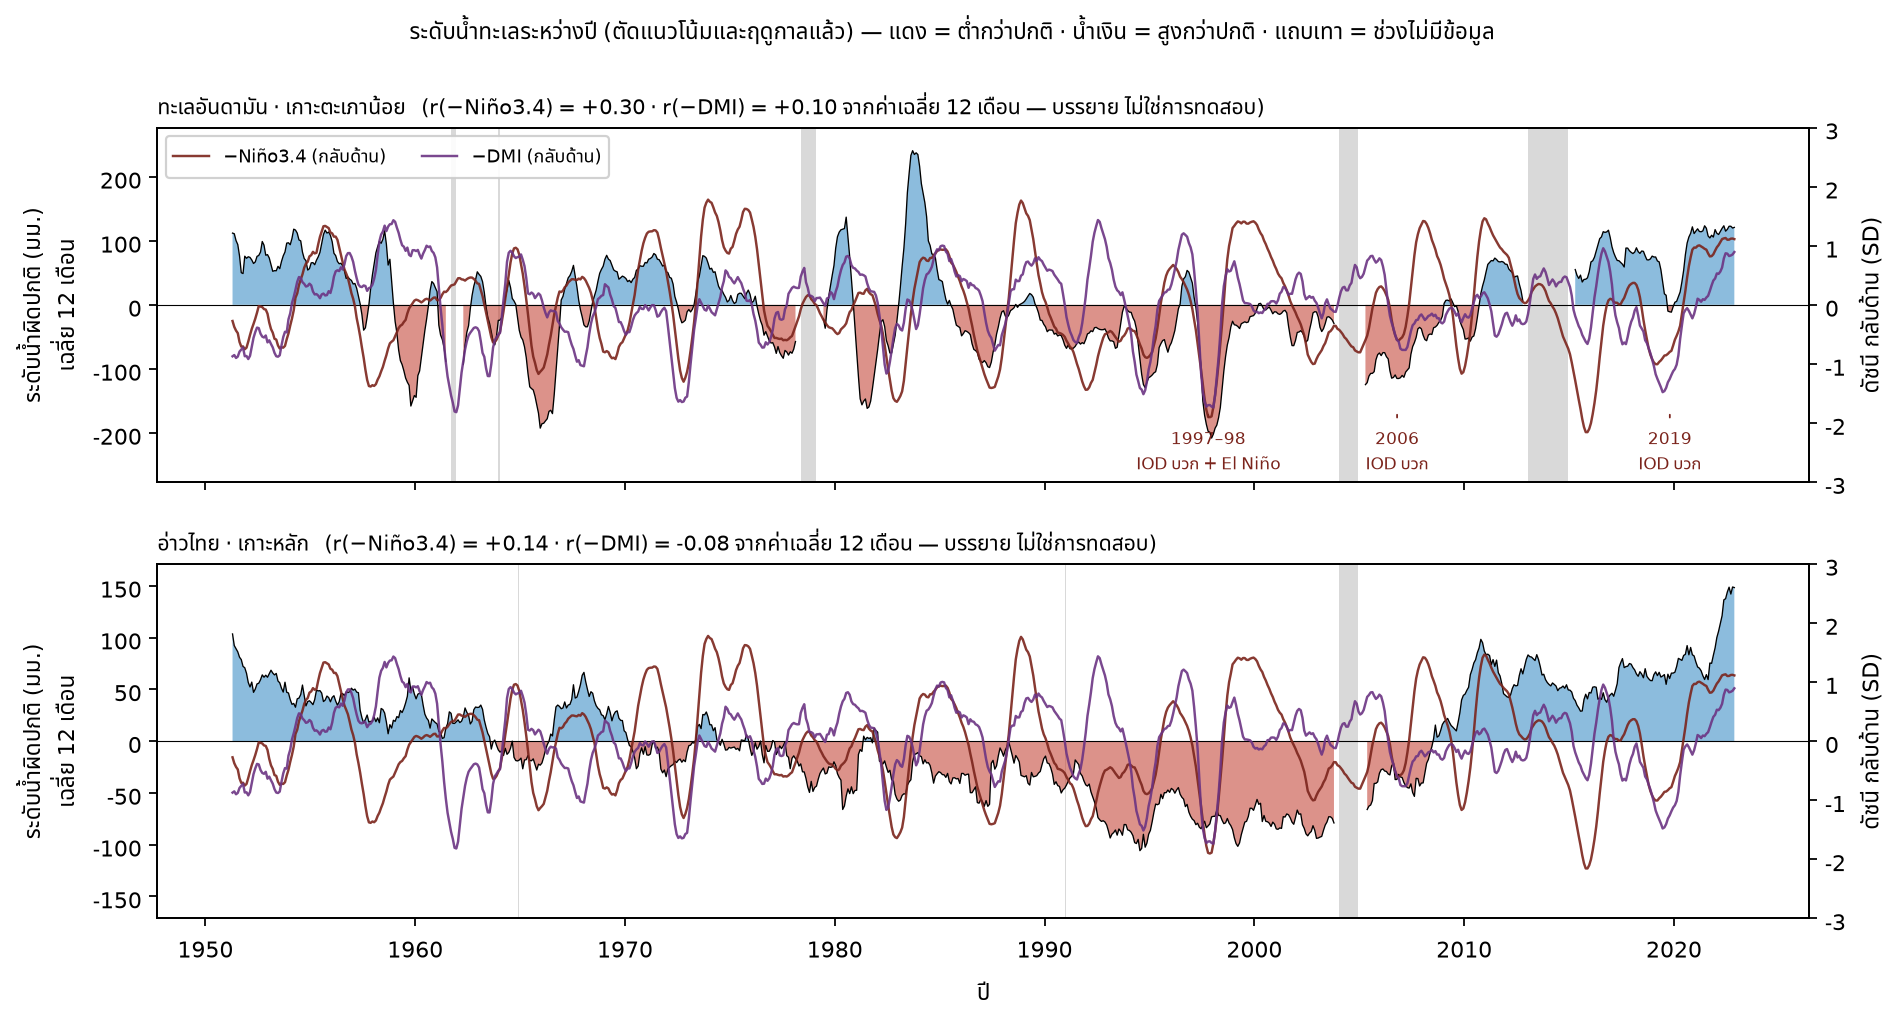

In [5]:
show("fig11_events")

**อ่านผล** — ปี 1997–98 ระดับน้ำอันดามันต่ำลงเกือบ 200 มม. (ค่าเฉลี่ย 12 เดือน) ตรงกับ El Niño + IOD บวก
แต่ r ทั้งอนุกรมกับ −DMI แค่ราว 0.1 เพราะความสัมพันธ์ "เปิด" เฉพาะช่วงเหตุการณ์ ⇒ ตัวอย่างที่ดีว่าทำไมต้องใช้
เครื่องมือที่ระบุตำแหน่งในเวลาได้ (WTC) แทนสหสัมพันธ์ ค่า r ตรงนี้เป็นการบรรยาย ไม่ใช่การทดสอบ

## 3 · PSMSL − UHSLC ของเกาะตะเภาน้อย แยกตามยุค

UHSLC ผ่านโซ่ Q7 (`wtc.series.q7_monthly` — ตัวกรองที่เราออกแบบเอง) · PSMSL หลังตัดค่าโดดใน `wtc/qc.py`
จัดศูนย์ที่มัธยฐานช่วง 1990–2003

In [6]:
from wtc.loaders import read_psmsl
from wtc.qc import apply_exclusions
from wtc.series import RAW, q7_monthly

tp, vp = read_psmsl(RAW / "psmsl" / "ko_taphao_noi_monthly.rlrdata")
vp, _ = apply_exclusions("ko_taphao_noi", tp, vp)
tu, vu = q7_monthly("ko_taphao_noi")
key = lambda tt: np.round((np.asarray(tt) - 1 / 24) * 12).astype(int)
up = dict(zip(key(tu), vu))
diff = np.array([v - up.get(k, np.nan) for k, v in zip(key(tp), vp)])
diff -= np.nanmedian(diff[(tp >= 1990) & (tp < 2004)])
eras = {"1990–2003": (1990, 2004), "2006–2012": (2006, 2013), "2015–2019": (2015, 2020)}
for name, (a, b) in eras.items():
    dd = diff[(tp >= a) & (tp < b)]; dd = dd[np.isfinite(dd)]
    print(f"{name}: n={len(dd):3d}  มัธยฐาน {np.median(dd):+7.1f} มม.  ช่วง [{dd.min():+.0f}, {dd.max():+.0f}]  MAD {np.median(np.abs(dd - np.median(dd))):.1f}")

early = diff[(tp >= 1990) & (tp < 2004)]; early = early[np.isfinite(early)]
late = diff[(tp >= 2015) & (tp < 2020)]; late = late[np.isfinite(late)]
assert np.median(np.abs(early)) < 3, "ยุคก่อน 2004 สองคลังต้องตรงกันระดับมิลลิเมตร"
assert 90 < np.median(late) < 110, "ยุค 2015–2019 ส่วนต่าง ≈ 100 มม. (UHSLC บวก 10 ซม. ให้ข้อมูลก่อน เม.ย. 2012)"
print("✅ ตรงกับที่รายงานเขียน: ตรงกันระดับ มม. ก่อน 2005 · ≈ +100 มม. หลัง 2015")

1990–2003: n=162  มัธยฐาน    +0.0 มม.  ช่วง [-36, +41]  MAD 1.2
2006–2012: n= 84  มัธยฐาน   +44.8 มม.  ช่วง [-70, +135]  MAD 40.3
2015–2019: n= 60  มัธยฐาน  +100.7 มม.  ช่วง [+86, +432]  MAD 1.1
✅ ตรงกับที่รายงานเขียน: ตรงกันระดับ มม. ก่อน 2005 · ≈ +100 มม. หลัง 2015


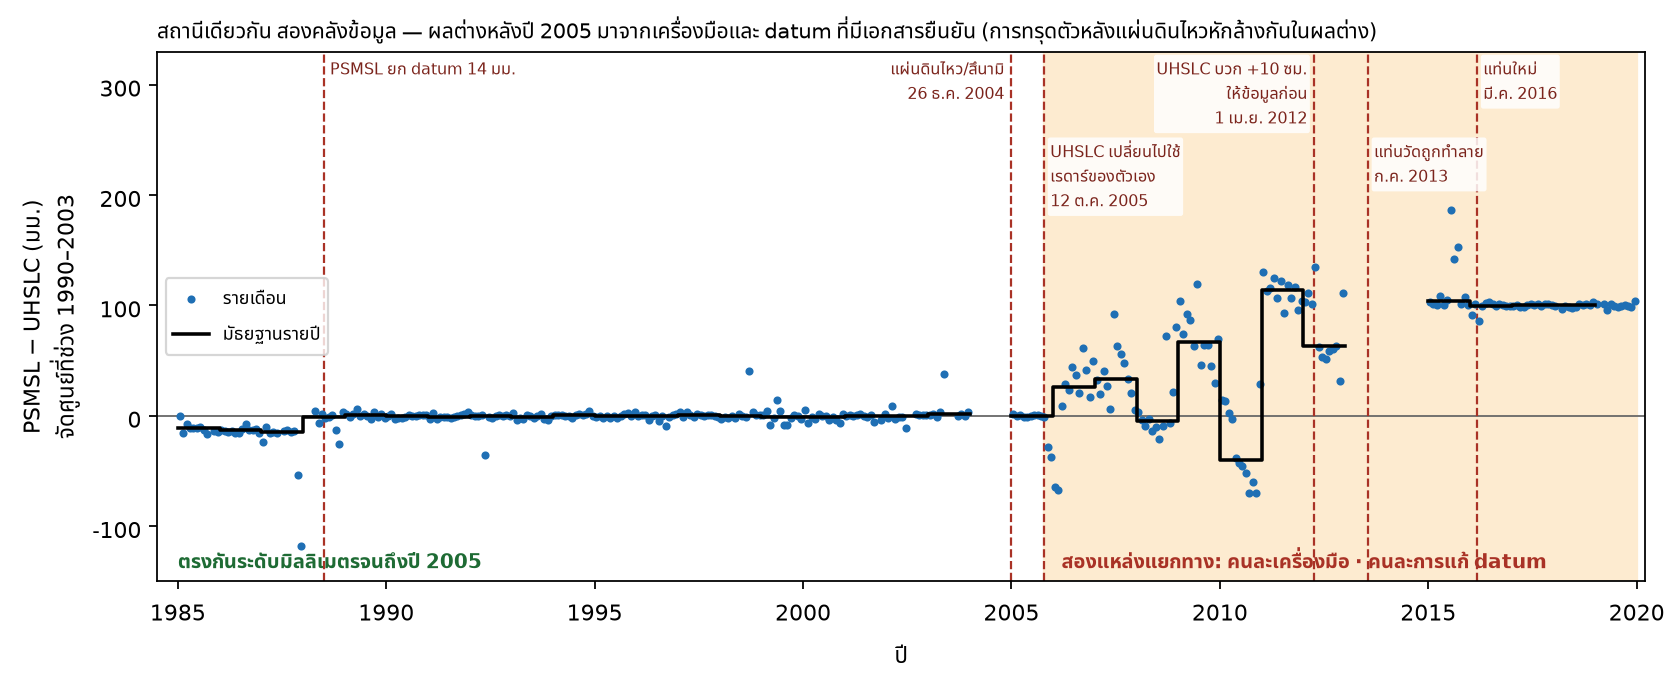

In [7]:
show("fig14_ktn_datum")

### ช่วงเวลาเดียวกัน ต่างแค่คลังข้อมูล — ดัชนีไหนขยับ

`short_1985` (PSMSL) กับ `y_q7` (UHSLC ผ่านโซ่ Q7) ใช้กริดเวลาเดียวกันเป๊ะ (`tests/test_series.py`)

In [8]:
S, M = I.load_sens()
b = "2–7 ปี"; A = "ko_taphao_noi"
src = {k: (S["short_1985"][A]["bands"][b]["single"][k]["pasc"], S["y_q7"][A]["bands"][b]["single"][k]["pasc"])
       for k in ("soi", "nino34", "wnpmi", "dmi")}
for k, (ps, uh) in src.items():
    print(f"{k:7s} PSMSL {ps:5.1f}%   UHSLC {uh:5.1f}%   อัตราส่วน {uh / ps:.2f}")
assert abs(src["soi"][1] / src["soi"][0] - 1) < 0.1, "SOI ไม่ควรขึ้นกับคลังข้อมูล"
assert src["wnpmi"][1] / src["wnpmi"][0] < 0.6, "WNPMI ลดลงราวครึ่งหนึ่งเมื่อเปลี่ยนเป็น UHSLC"

soi     PSMSL  49.7%   UHSLC  50.3%   อัตราส่วน 1.01
nino34  PSMSL  39.1%   UHSLC  43.1%   อัตราส่วน 1.10
wnpmi   PSMSL  70.5%   UHSLC  34.9%   อัตราส่วน 0.49
dmi     PSMSL  22.0%   UHSLC  23.3%   อัตราส่วน 1.06


## 4 · สัญญาณไฟความแข็งแรง

เกณฑ์ของแต่ละข้อสรุปอยู่ใน `make_infographics.robustness_rows` (เกณฑ์เดียวกับตารางใน PROGRESS.md W7)

In [9]:
rows = I.robustness_rows(S)
names = list(S)
counts = {}
for label, f in rows:
    v = [f(n) for n in names]
    counts[label] = sum(x == 2 for x in v)
    print(f"{counts[label]}/{len(names)}  {label}   " + " ".join({2: '✓', 1: '~', 0: '✗'}[x] for x in v))

assert len(names) == 8
lab = [r[0] for r in rows]
assert counts[lab[0]] == counts[lab[1]] == counts[lab[2]] == counts[lab[3]] == 8   # ข้อสรุปหลัก 8/8
assert counts[lab[4]] == 5 and counts[lab[5]] == 6 and counts[lab[6]] == 4           # 🟡 ตาม PROGRESS.md
print("✅ ตรงกับตาราง \"ข้อสรุปที่ปรับแล้ว\" ใน PROGRESS.md")

8/8  อันดามันสัมพันธ์กับดัชนีภูมิอากาศ (ดัชนีเดี่ยว p < 0.05)   ✓ ✓ ✓ ✓ ✓ ✓ ✓ ✓
8/8  อ่าวไทยไม่มีดัชนีเดี่ยวใดเกิน noise   ✓ ✓ ✓ ✓ ✓ ✓ ✓ ✓
8/8  SOI · DMI · WNPMI · Niño3.4 เกิน noise ทั้งสี่ตัว   ✓ ✓ ✓ ✓ ✓ ✓ ✓ ✓
8/8  ดัชนีเดียวพอ (ทั้งระนาบ)   ✓ ✓ ✓ ✓ ✓ ✓ ✓ ✓
5/8  ดัชนีเดียวพอ (แถบ 2–7 ปี)   ✓ ✗ ✓ ✓ ✓ ✓ ✗ ✗
6/8  WNPMI อันดับหนึ่งในแถบ 2–7 ปี   ✓ ✓ ✓ ✓ ✓ ✓ ✗ ✗
4/8  ดัชนีภูมิภาคเพิ่มอำนาจอธิบาย (Q5, แถบ 2–7 ปี)   ✓ ~ ✓ ✗ ✓ ✓ ~ ✗
✅ ตรงกับตาราง "ข้อสรุปที่ปรับแล้ว" ใน PROGRESS.md


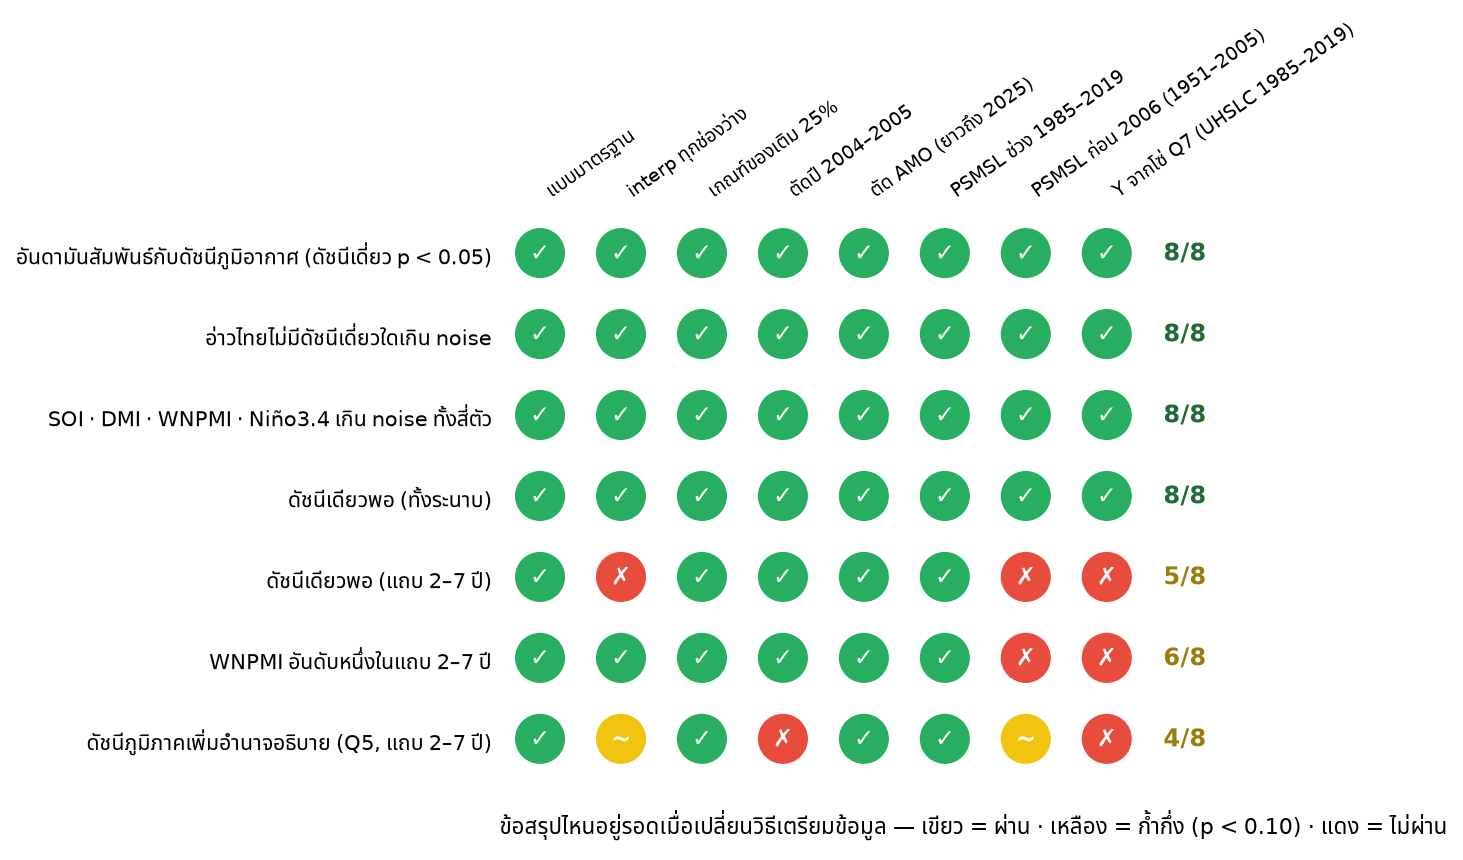

In [10]:
show("fig13_robustness")

## 5 · รูปเชิงสื่อสารที่เหลือของรายงาน

แผนที่สามรูปใช้ข้อเท็จจริงทางภูมิศาสตร์ (พิกัดสถานีจาก PSMSL · กล่องของดัชนีตามนิยาม) และข้อความผลสร้างจากไฟล์ผล

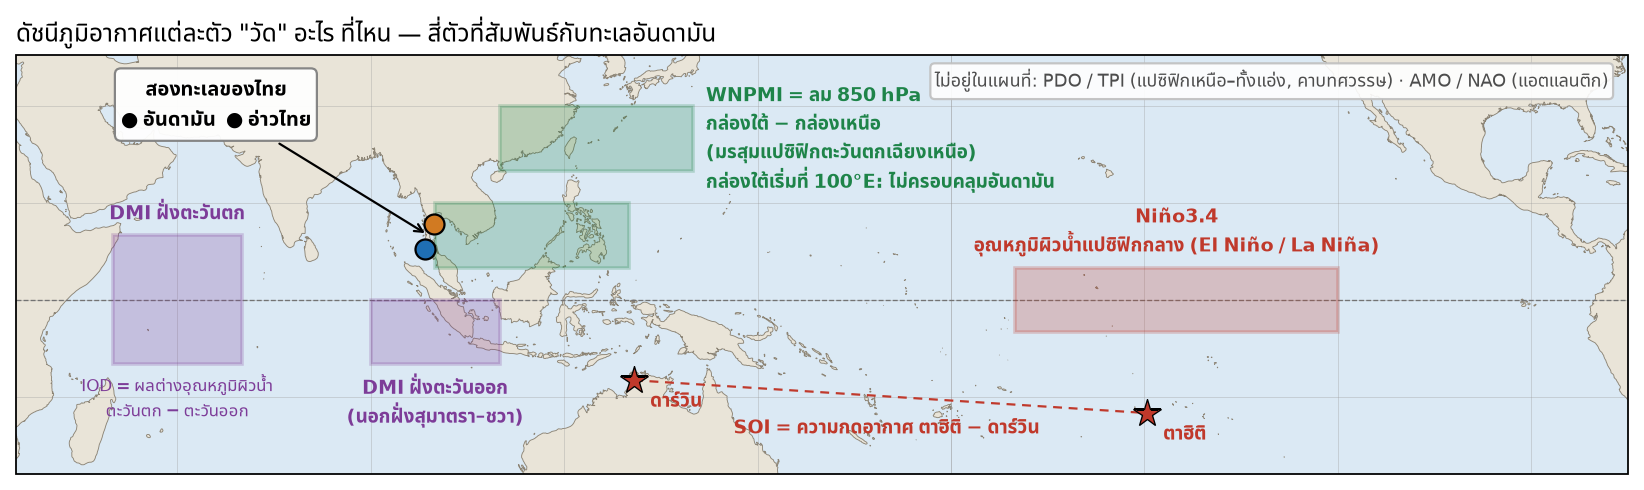

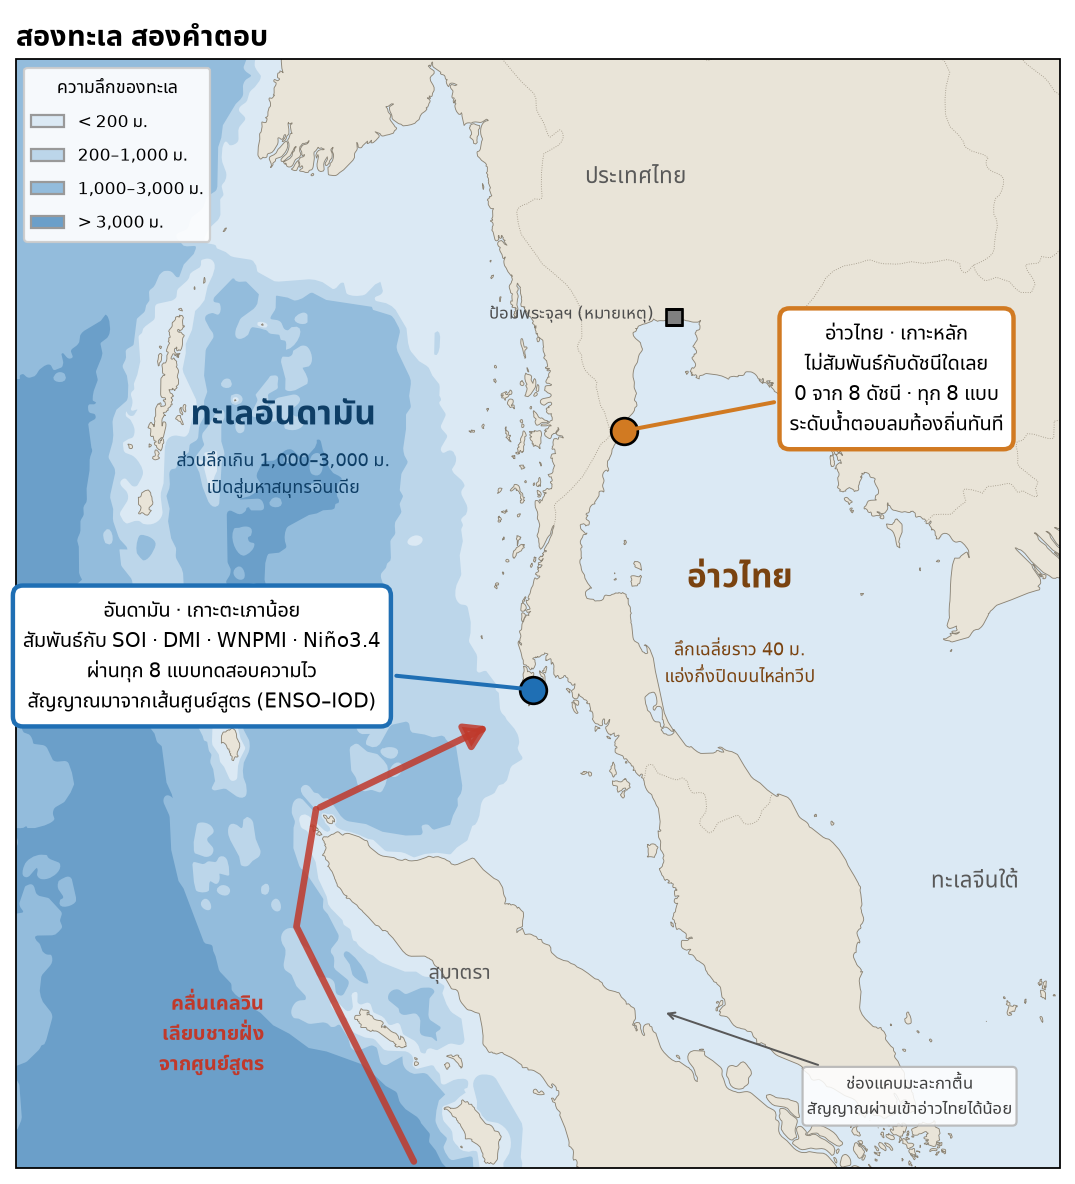

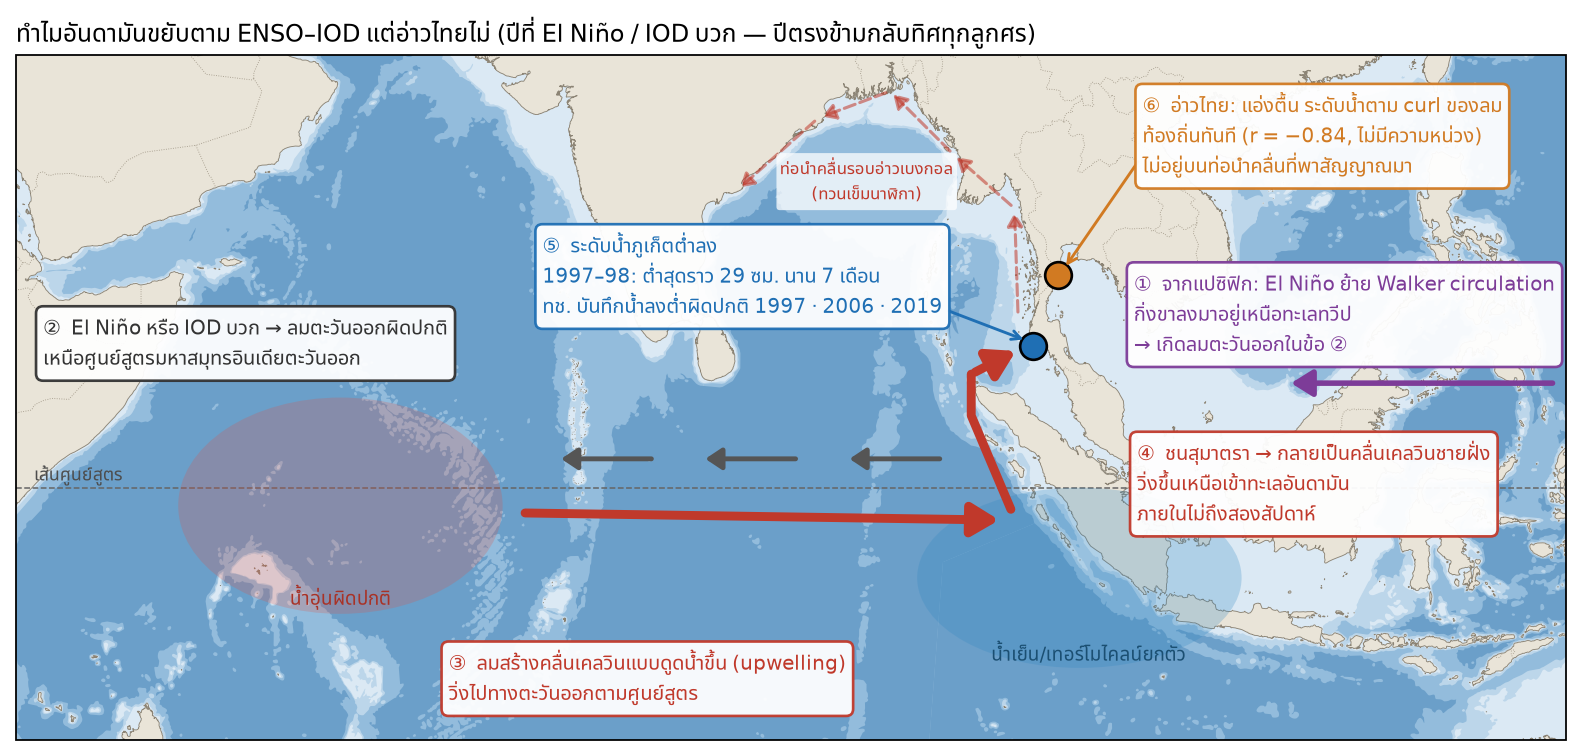

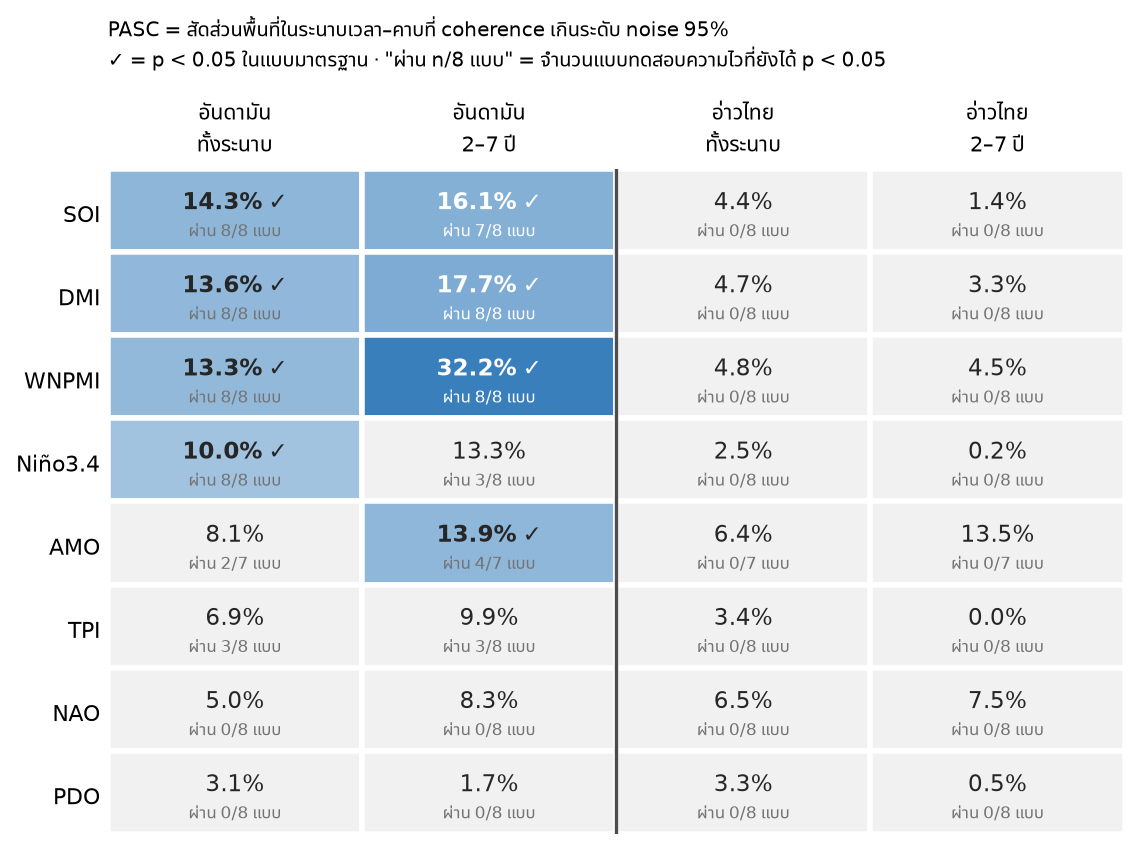

In [11]:
for name in ("map01_indices", "map02_two_seas", "map03_mechanism", "fig10_scorecard"):
    show(name)

## สรุป

| ตรวจ | ผล |
| --- | --- |
| ทิศของความสัมพันธ์ที่อันดามันตรงกลไก | ✓ ทั้ง 4 ดัชนี (SOI −28°, Niño3.4 +156°, DMI −150°, WNPMI +56°) |
| ความสัมพันธ์มาเป็นช่วง | ✓ 1997–98 ต่ำ < −150 มม. แต่ r ทั้งอนุกรมกับ −DMI < 0.3 |
| PSMSL − UHSLC | ✓ ตรงกันระดับ มม. ก่อน 2004 · ≈ +100 มม. ช่วง 2015–2019 |
| เปลี่ยนคลังข้อมูล | SOI ไม่ขยับ · WNPMI ลดราวครึ่ง |
| สัญญาณไฟ | ✓ ตรงกับ PROGRESS.md (4 ข้อ 8/8 · 5/8 · 6/8 · 4/8) |